# Estimating power-law exponents: log-log fits vs MLE
*Companion notebook to Gould et al., "Limit order books", Section III.J.1*

## The question
The survey warns that many published power-law exponents for LOB data are unreliable because people fit a straight line on a log-log plot. We will test that claim directly:

1. **Simulate** data from a power law whose exponent we *choose* (so we know the right answer).
2. **Estimate** the exponent back using several methods.
3. **Compare** each estimate with the truth, over many repeated samples, so we can measure bias and variance.
4. **Check goodness of fit**: does the fitted model actually describe the data, or is it just a number?

## Convention (same as the paper)
A random variable $Z$ has a power-law tail with exponent $\alpha$ if, for $z \ge z_{\min}$,

$$f(z) = \frac{\alpha-1}{z_{\min}}\left(\frac{z}{z_{\min}}\right)^{-\alpha}, \qquad \alpha>1 .$$

The probability of exceeding $z$ (the **CCDF**, complementary cumulative distribution function) is

$$P(Z>z) = \left(\frac{z}{z_{\min}}\right)^{-(\alpha-1)} .$$

On log-log axes both are straight lines: the density has slope $-\alpha$ and the CCDF has slope $-(\alpha-1)$.

> **Naming clash to avoid:** this $\alpha$ is the *density tail exponent*. It is **not** the long-memory exponent $\alpha$ (autocorrelation decay) from III.J.2, even though the paper uses the same letter.

## Roadmap
| Part | What we do |
|---|---|
| 0 | Setup, samplers, estimators, goodness-of-fit tools |
| 1 | Sanity check, then fits and goodness of fit on single samples |
| 2 | Monte Carlo over 300 samples: bias and variance of each estimator |
| 3 | Does more data fix the bias? |
| 4 | Conclusions and exercises |

# Part 0: Setup

## Step 0.1: imports and constants
**What we do:** import the libraries, fix a random seed so the results are reproducible, and set the *true* exponent we will try to recover.

**Why these values:** $\alpha = 2.5$ is in the range reported for LOB quantities (the paper quotes values between about 1 and 3). In "scenario B" later, the power law only begins at $z = 5$, to mimic real data where only the far tail follows a power law.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
ALPHA_TRUE = 2.5       # the answer we will try to recover
ZMIN_TRUE_B = 5.0      # in scenario B the power law only starts here

rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})

## Step 0.2: generating data with a known exponent
**What we do:** write two samplers.

**Sampler 1, pure power law (inverse-CDF method).** If $U$ is uniform on $(0,1)$ and $F$ is a CDF, then $F^{-1}(U)$ has CDF $F$. Our CDF is $F(z)=1-(z/z_{\min})^{-(\alpha-1)}$. Setting $u=F(z)$ and solving for $z$:

$$z = z_{\min}\,(1-u)^{-1/(\alpha-1)} .$$

So we draw uniforms and apply this formula.

**Sampler 2, bulk + tail.** Real data rarely follows a power law everywhere. We mix:
- a **lognormal bulk** truncated to values below $z_{\min}$ (the "ordinary" orders), with
- a **power-law tail** above $z_{\min}$ (the rare, extreme ones), making up about 30% of the sample.

**Why:** scenario B lets us test something that matters for real data: what happens when you do not know where the power law starts.

In [2]:
def sample_powerlaw(n, alpha, zmin, rng):
    # Inverse-CDF sampling: z = zmin * (1-u)^(-1/(alpha-1))
    u = rng.random(n)
    return zmin * (1.0 - u) ** (-1.0 / (alpha - 1.0))


def sample_bulk_plus_tail(n, alpha, zmin, tail_frac, rng, mu=0.8, sigma=0.7):
    # Lognormal bulk (truncated below zmin) + power-law tail above zmin.
    n_tail = rng.binomial(n, tail_frac)
    tail = sample_powerlaw(n_tail, alpha, zmin, rng)
    need = n - n_tail
    bulk = np.empty(0)
    while len(bulk) < need:                  # rejection: keep draws below zmin
        d = rng.lognormal(mu, sigma, 3 * need + 10)
        bulk = np.concatenate([bulk, d[d < zmin]])
    return np.concatenate([bulk[:need], tail])

## Step 0.3: the four estimators
**What we do:** implement the ways of estimating $\alpha$ from data. Each takes the data `x` and a threshold `zmin` and uses only observations $\ge z_{\min}$.

**1. OLS on a linear-bin histogram.** Build a histogram with equal-width bins, convert counts to a density, take logs of both axes, and fit a straight line by least squares. The estimate is $\hat\alpha = -\text{slope}$. This is the "naive" approach.

**2. OLS on a log-bin histogram.** The same, but with bins that get wider geometrically. This is a common fix for the sparse tail.

**3. OLS on the empirical CCDF.** Sort the data, compute $P(Z>z)$ at each point, and fit a line on log-log axes. Since the CCDF slope is $-(\alpha-1)$, we use $\hat\alpha = 1-\text{slope}$.

**4. Maximum likelihood (MLE).** For $n$ observations above $z_{\min}$, the log-likelihood is

$$\ell(\alpha) = n\ln(\alpha-1) - n\ln z_{\min} - \alpha\sum_i \ln\frac{z_i}{z_{\min}} .$$

Setting $\ell'(\alpha)=0$ gives a closed form:

$$\hat\alpha = 1 + \frac{n}{\sum_i \ln(z_i/z_{\min})} .$$

No binning and no regression: every raw observation is used directly.

**Why compare all four:** methods 1-3 are what people do in practice. Method 4 is what Clauset et al. (2009) recommend.

In [3]:
def mle_alpha(x, zmin):
    t = x[x >= zmin]
    return 1.0 + len(t) / np.sum(np.log(t / zmin))


def ols_linbins(x, zmin, nb=30):
    t = x[x >= zmin]
    edges = np.linspace(zmin, t.max(), nb + 1)          # equal-width bins
    counts, _ = np.histogram(t, edges)
    w = np.diff(edges)
    c = 0.5 * (edges[1:] + edges[:-1])                  # bin centres
    dens = counts / (len(t) * w)                        # counts -> density
    m = counts > 0                                      # log(0) is undefined
    return -np.polyfit(np.log(c[m]), np.log(dens[m]), 1)[0]


def ols_logbins(x, zmin, nb=20):
    t = x[x >= zmin]
    edges = np.geomspace(zmin, t.max(), nb + 1)         # geometrically widening bins
    counts, _ = np.histogram(t, edges)
    w = np.diff(edges)
    c = np.sqrt(edges[1:] * edges[:-1])                 # geometric centres
    dens = counts / (len(t) * w)
    m = counts > 0
    return -np.polyfit(np.log(c[m]), np.log(dens[m]), 1)[0]


def ols_ccdf(x, zmin):
    t = np.sort(x[x >= zmin])
    n = len(t)
    ccdf = (n - np.arange(n)) / n                       # P(Z >= t_i), always > 0
    slope = np.polyfit(np.log(t), np.log(ccdf), 1)[0]
    return 1.0 - slope                                  # CCDF slope = -(alpha-1)


def all_estimators(x, zmin):
    return {
        "OLS lin-bin hist": ols_linbins(x, zmin),
        "OLS log-bin hist": ols_logbins(x, zmin),
        "OLS CCDF": ols_ccdf(x, zmin),
        "MLE": mle_alpha(x, zmin),
    }

## Step 0.4: goodness of fit and choosing $z_{\min}$
**What we do:** build the tools that answer two questions the four estimators above cannot: *where does the power law start?* and *is a power law even a good description?*

**KS distance.** Compare the empirical CDF of the tail data with the fitted model's CDF, and take the largest vertical gap:

$$D=\max_z\,|F_{\text{emp}}(z)-F_{\text{model}}(z)| .$$

Small $D$ means the model hugs the data.

**Choosing $z_{\min}$ (Clauset et al.).** Try many candidate thresholds. For each, estimate $\alpha$ by MLE on the data above it and compute $D$. Pick the threshold with the smallest $D$. Too low, and non-power-law bulk contaminates the fit (large $D$). Too high, and little data is left (noisy, but $D$ can be small, so we also enforce a minimum tail size of 50).

**Bootstrap p-value.** A small $D$ is not informative by itself: how small is small? So we:
1. generate many synthetic datasets that *really are* power laws with our fitted $\hat\alpha$ (keeping the observed data below $z_{\min}$),
2. re-fit each one from scratch (including re-estimating $z_{\min}$) and compute its $D$,
3. report $p$ = the fraction of synthetic $D$'s at least as large as the observed $D$.

**How to read $p$:** if real data would look this far from a power law only rarely among genuine power-law samples ($p<0.1$), we **reject** the power-law hypothesis. A large $p$ means only that the power law is *plausible*, not proven.

In [4]:
def ks_stat(t, alpha, zmin):
    t = np.sort(t)
    n = len(t)
    model = 1.0 - (t / zmin) ** (-(alpha - 1.0))        # model CDF at the data points
    hi = np.arange(1, n + 1) / n                        # empirical CDF just after each point
    lo = np.arange(0, n) / n                            # ... and just before
    return max(np.max(np.abs(hi - model)), np.max(np.abs(lo - model)))


def fit_clauset(x, n_cand=60, min_tail=50):
    # MLE for alpha, with zmin chosen to minimise the KS distance.
    xs = np.sort(x)
    n = len(xs)
    idxs = np.unique(np.linspace(0, n - min_tail, n_cand).astype(int))
    best = (np.inf, None, None, None)
    for i in idxs:
        zmin = xs[i]
        t = xs[i:]
        a = 1.0 + len(t) / np.sum(np.log(t / zmin))
        d = ks_stat(t, a, zmin)
        if d < best[0]:
            best = (d, a, zmin, len(t))
    d, a, z, k = best
    return a, z, d, k                                   # alpha_hat, zmin_hat, D, tail size


def gof_pvalue(x, alpha, zmin, D, rng, reps=200):
    # Semi-parametric bootstrap p-value: P(D_synthetic >= D_observed).
    n = len(x)
    below = x[x < zmin]
    p_tail = np.mean(x >= zmin)
    ds = []
    for _ in range(reps):
        k = rng.binomial(n, p_tail)
        tail = sample_powerlaw(k, alpha, zmin, rng)               # a genuine power-law tail
        bulk = rng.choice(below, n - k) if len(below) else np.empty(0)
        _, _, d, _ = fit_clauset(np.concatenate([tail, bulk]))    # full re-fit each time
        ds.append(d)
    return float(np.mean(np.array(ds) >= D))

# Part 1: Single samples

## Step 1.1: sanity check with a huge sample
**What we do:** draw a pure power-law sample with $n=200{,}000$ and run all four estimators with the true $z_{\min}=1$.

**Why:** before trusting any simulation, check the machinery works in the easy case. With this much data, a *consistent* estimator should land very close to 2.5. If an estimator is still far off, the problem is the method, not a lack of data. That separates "noisy" from "biased".

This cell uses its own random generator so that the later results do not depend on it.

In [5]:
rng_check = np.random.default_rng(123)
x_big = sample_powerlaw(200_000, ALPHA_TRUE, 1.0, rng_check)

pd.Series(all_estimators(x_big, 1.0), name="alpha_hat (n=200,000)").round(3).to_frame()

,"alpha_hat (n=200,000)"
OLS lin-bin hist,2.619
OLS log-bin hist,2.460
OLS CCDF,2.496
MLE,2.496


### What we see
| Method | $\hat\alpha$ (n = 200,000, true = 2.5) |
|---|---|
| OLS linear-bin histogram | 2.619 |
| OLS log-bin histogram | 2.460 |
| OLS CCDF | 2.496 |
| MLE | 2.496 |

### What we infer
- **The machinery works.** MLE and the CCDF fit land at 2.496. The MLE's standard error is about $(\alpha-1)/\sqrt{n}=1.5/\sqrt{200000}\approx0.003$, so 2.496 is within roughly one standard error of the truth.
- **The histogram fits are still off with 200,000 points.** The log-bin version is 0.04 low, and the linear-bin version is 0.12 *high*. That is not a data shortage: it is the *method*.
- **The linear-bin error even changes sign** (Part 3 will show it was far too low at small $n$ and has now overshot). An estimate that swings from too low to too high depends on arbitrary choices (30 equal-width bins stretched up to the sample maximum), not just on the data. That is a bad property in a measurement.

## Step 1.2: create three datasets
**What we do:** generate three samples that we will analyse one by one:

- **A:** a pure power law with $\alpha=2.5$ starting at 1 ($n=1000$).
- **B:** lognormal bulk + power-law tail with $\alpha=2.5$ starting at 5 ($n=1000$). About 30% of points are in the tail.
- **C:** a pure lognormal ($n=3000$). This is *not* a power law at all.

**Why C:** MLE will happily return an exponent for any heavy-looking data. C tests whether our goodness-of-fit step can notice that the model is wrong. In real LOB work you will not know which of these three situations you are in, which is exactly why the check is needed.

In [6]:
samples = {
    "A: pure power law (alpha=2.5)": sample_powerlaw(1000, ALPHA_TRUE, 1.0, rng),
    "B: lognormal bulk + power-law tail (alpha=2.5, zmin=5)":
        sample_bulk_plus_tail(1000, ALPHA_TRUE, ZMIN_TRUE_B, 0.3, rng),
    "C: pure lognormal (NOT a power law)": rng.lognormal(0.0, 1.0, 3000),
}
for k, v in samples.items():
    print(f"{k:<58s} n={len(v):5d}  min={v.min():.3g}  median={np.median(v):.3g}  max={v.max():.3g}")

A: pure power law (alpha=2.5)                              n= 1000  min=1  median=1.58  max=108
B: lognormal bulk + power-law tail (alpha=2.5, zmin=5)     n= 1000  min=0.264  median=2.66  max=721
C: pure lognormal (NOT a power law)                        n= 3000  min=0.0124  median=1.01  max=31.6


### What we see and infer
- **A:** minimum 1, as built. The median is 1.58. For a power law the median is $z_{\min}\cdot 2^{1/(\alpha-1)} = 2^{2/3}\approx1.59$, so the sampler is working as intended.
- **B:** values start below 1 (the lognormal bulk) and reach 721. A maximum hundreds of times the median is the signature of a heavy tail.
- **C:** the maximum is only about 32 even with 3000 points. Lognormal tails are heavy compared with a normal distribution but lighter than a power law's; this will matter when we ask whether C "looks like" a power law.

## Step 1.3: why a log-log plot is used, and why it can mislead
**What we do:** for sample B, plot the same data twice: as an ordinary histogram, and as a CCDF on log-log axes.

**Why:** on ordinary axes a heavy-tailed sample looks like a tall spike near zero and nothing else; the tail is invisible. The log-log CCDF reveals the tail, and for a power law it shows as a straight line. Notice also that B's CCDF is *not* a straight line everywhere: it bends. That bend is the transition from bulk to tail, and it is the root of the $z_{\min}$ problem.

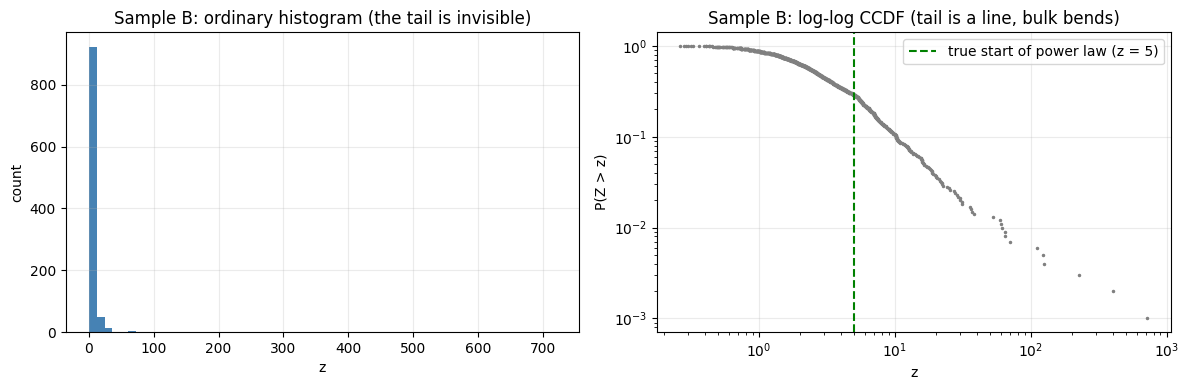

In [7]:
xB = samples["B: lognormal bulk + power-law tail (alpha=2.5, zmin=5)"]
xs = np.sort(xB)
ccdf = (len(xs) - np.arange(len(xs))) / len(xs)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(xB, bins=60, color="steelblue")
ax[0].set_title("Sample B: ordinary histogram (the tail is invisible)")
ax[0].set_xlabel("z"); ax[0].set_ylabel("count")

ax[1].loglog(xs, ccdf, ".", ms=3, color="grey")
ax[1].axvline(ZMIN_TRUE_B, color="g", ls="--", label="true start of power law (z = 5)")
ax[1].set_title("Sample B: log-log CCDF (tail is a line, bulk bends)")
ax[1].set_xlabel("z"); ax[1].set_ylabel("P(Z > z)"); ax[1].legend()
plt.tight_layout(); plt.show()

### What we see and infer
- **Left (ordinary histogram):** with 60 equal-width bins stretched to a maximum of about 700, almost every observation falls into the first bin or two. The tail that we care about is invisible. This is why heavy-tailed data is always inspected on log axes.
- **Right (log-log CCDF):** the far tail is close to a straight line, while the bulk curves. The bend sits around the green line at $z=5$.
- **The consequence for estimation:** a straight-line fit over *all* the data averages a curved part and a straight part. The result is meaningless for both, and its value depends on how many bulk points you have. Choosing where the tail starts is therefore not a detail; it is half of the problem.

## Step 1.4: fit all methods to each sample and test goodness of fit
**What we do:** for each of A, B, C:

1. run the three OLS methods on **all** the data (what a practitioner would do without knowing where the power law starts),
2. run Clauset's procedure: MLE with $z_{\min}$ estimated by minimising the KS distance,
3. compute the bootstrap p-value for that fit,
4. plot the empirical CCDF with each fitted model on top.

**How to read the plot:** grey dots are the data. Each line is the power law implied by an estimated $\alpha$. The OLS lines are anchored at the smallest data point; the MLE line starts at the estimated $z_{\min}$ (the vertical band). A good fit means the line sits on top of the dots over its range.

This is the cell that uses the bootstrap, so it takes a little while to run.

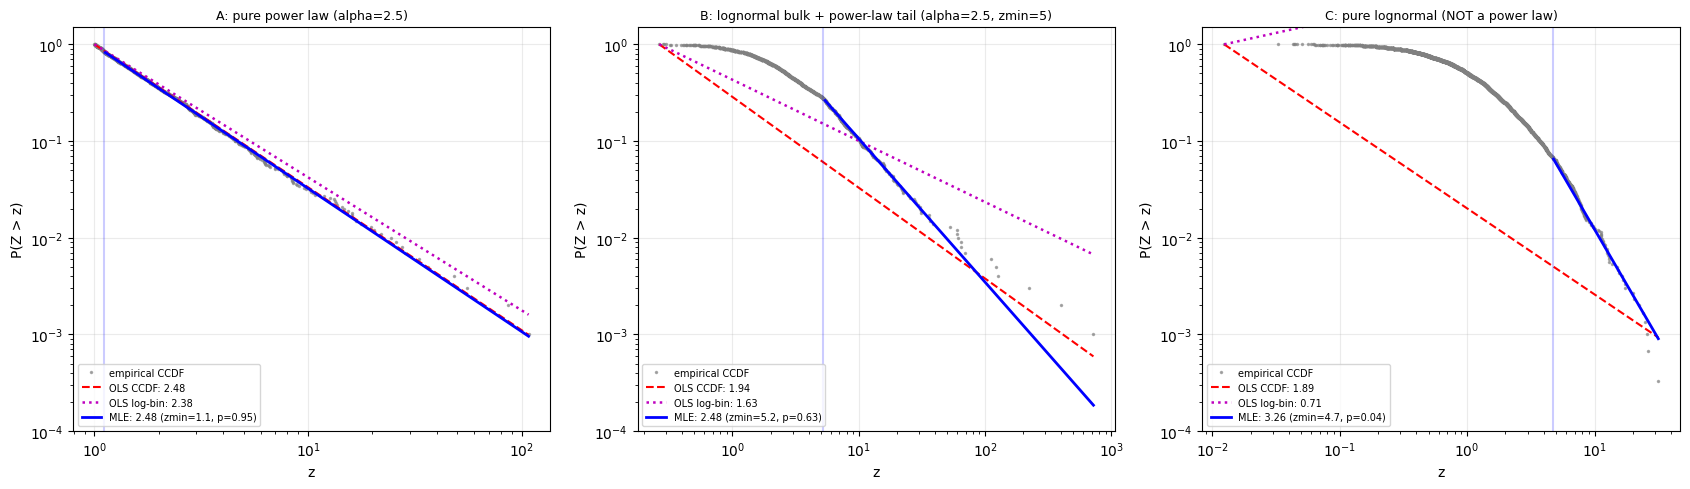

,OLS lin-bin,OLS log-bin,OLS CCDF,MLE + est. zmin,zmin_hat,tail n,KS D,p-value,verdict
sample,,,,,,,,,
A:,1.845,2.376,2.479,2.481,1.111,839,0.015,0.955,plausible
B:,1.602,1.632,1.939,2.483,5.233,276,0.035,0.630,plausible
C:,2.253,0.708,1.890,3.260,4.717,200,0.054,0.045,REJECTED


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
rows = []
for ax, (name, x) in zip(axes, samples.items()):
    zmin_all = x.min()
    est = {
        "OLS lin-bin (all data)": ols_linbins(x, zmin_all),
        "OLS log-bin (all data)": ols_logbins(x, zmin_all),
        "OLS CCDF (all data)": ols_ccdf(x, zmin_all),
    }
    a_c, z_c, d_c, k_c = fit_clauset(x)
    p = gof_pvalue(x, a_c, z_c, d_c, rng, reps=200)

    rows.append({"sample": name[:2], **{k.split(" (")[0]: v for k, v in est.items()},
                 "MLE + est. zmin": a_c, "zmin_hat": z_c, "tail n": k_c,
                 "KS D": d_c, "p-value": p,
                 "verdict": "plausible" if p >= 0.1 else "REJECTED"})

    xs = np.sort(x)
    ccdf = (len(xs) - np.arange(len(xs))) / len(xs)
    ax.loglog(xs, ccdf, ".", ms=3, color="grey", alpha=0.6, label="empirical CCDF")
    grid = np.geomspace(xs[0], xs[-1], 200)
    ax.loglog(grid, (grid / zmin_all) ** (-(est["OLS CCDF (all data)"] - 1)),
              "r--", lw=1.5, label=f"OLS CCDF: {est['OLS CCDF (all data)']:.2f}")
    ax.loglog(grid, (grid / zmin_all) ** (-(est["OLS log-bin (all data)"] - 1)),
              "m:", lw=1.8, label=f"OLS log-bin: {est['OLS log-bin (all data)']:.2f}")
    g2 = grid[grid >= z_c]
    ax.loglog(g2, (k_c / len(xs)) * (g2 / z_c) ** (-(a_c - 1)),
              "b-", lw=2, label=f"MLE: {a_c:.2f} (zmin={z_c:.1f}, p={p:.2f})")
    ax.axvline(z_c, color="b", alpha=0.2)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("z"); ax.set_ylabel("P(Z > z)"); ax.set_ylim(1e-4, 1.5)
    ax.legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()

pd.DataFrame(rows).set_index("sample").round(3)

### What we see
| Sample | OLS lin-bin | OLS log-bin | OLS CCDF | MLE + est. $z_{\min}$ | $\hat z_{\min}$ | tail n | KS $D$ | p-value | verdict |
|---|---|---|---|---|---|---|---|---|---|
| A (true $\alpha$ = 2.5) | 1.845 | 2.376 | 2.479 | **2.481** | 1.11 | 839 | 0.015 | 0.955 | plausible |
| B (true $\alpha$ = 2.5) | 1.602 | 1.632 | 1.939 | **2.483** | 5.23 | 276 | 0.035 | 0.630 | plausible |
| C (not a power law) | 2.253 | 0.708 | 1.890 | **3.260** | 4.72 | 200 | 0.054 | 0.045 | REJECTED |

### What we infer
**Sample A (clean power law).**
- MLE and the CCDF fit are close to the truth (2.48), and the linear-bin fit is far off (1.85).
- Clauset's procedure picked $\hat z_{\min}=1.11$ rather than the true 1. It discarded 161 points to reach the lowest KS distance, which is slightly wasteful but harmless.
- $p=0.955$: the data are entirely consistent with a power law, as they should be.

**Sample B (bulk + tail).**
- All three OLS fits on all the data are wrong (1.60 to 1.94). In the plot the red and magenta lines cut through the bulk and match neither region.
- Clauset's procedure found the start of the tail on its own ($\hat z_{\min}=5.23$ against a true 5) and then estimated $\alpha=2.48$. The blue line sits on the dots from there onward. About 276 of the roughly 300 genuine tail points were used.
- **This is the central lesson of III.J.1:** the main skill in estimating a tail exponent is finding the tail, not drawing the line.

**Sample C (not a power law).**
- The log-bin OLS gives 0.708. An exponent below 1 is not even valid for a normalisable density, which shows how unreliable that method is on misspecified data.
- **MLE returns 3.26**, a reasonable-looking number (it even resembles the "inverse cubic law" from the paper's IV.G). Without the goodness-of-fit step you could report it and be wrong.
- The bootstrap gives $p=0.045$, so the power law is rejected. **But this is borderline**, from one sample and 200 bootstrap replications, so treat it as a warning rather than a verdict. The honest reading is that a lognormal tail is hard to tell apart from a power law at this sample size, which is a known difficulty and one reason the literature debates these claims.

**General points.**
- The KS distance $D$ is not comparable between samples, because it depends on the tail size. The p-value accounts for that, which is why we use it.
- A large p-value means the power law is *plausible*, not *proven*. Other distributions (such as the lognormal here) can also pass.

# Part 2: Monte Carlo, bias and variance over many samples

## Step 2.1: repeat the experiment 300 times
**What we do:** a single sample can be lucky or unlucky, so we repeat each scenario 300 times (fresh data each time, $n=1000$) and record every estimate.

- **Scenario A:** pure power law, with $z_{\min}=1$ known to every method.
- **Scenario B (naive):** bulk + tail, and each method is run on **all** the data (using the smallest observation as $z_{\min}$), as someone who doesn't know where the power law starts would do.
- **Scenario B (oracle):** same data, but every method is *told* the true $z_{\min}=5$. This separates two failure sources: "wrong method" versus "wrong region".
- We also record Clauset's MLE with $z_{\min}$ **estimated** from the data, the realistic best practice.

**Why:** the distribution of estimates tells us about both **bias** (is the average estimate wrong?) and **variance** (how much does it scatter?).

In [9]:
def collect(dicts_list):
    keys = dicts_list[0].keys()
    return {k: np.array([d[k] for d in dicts_list]) for k in keys}

reps, n = 300, 1000
A_runs, Bn_runs, Bo_runs, Bc_runs = [], [], [], []
for _ in range(reps):
    xa = sample_powerlaw(n, ALPHA_TRUE, 1.0, rng)
    A_runs.append(all_estimators(xa, 1.0))

    xb = sample_bulk_plus_tail(n, ALPHA_TRUE, ZMIN_TRUE_B, 0.3, rng)
    Bn_runs.append(all_estimators(xb, xb.min()))            # naive: use all data
    Bo_runs.append(all_estimators(xb, ZMIN_TRUE_B))         # oracle: true zmin given
    Bc_runs.append(fit_clauset(xb)[0])                      # MLE + estimated zmin

A  = collect(A_runs)
Bn = collect(Bn_runs)
Bo = collect(Bo_runs)
Bc = np.array(Bc_runs)
print("done:", reps, "replications per scenario")

done: 300 replications per scenario


## Step 2.2: summarise as tables
**What we do:** for every estimator and scenario compute

- **mean**: the average estimate over 300 runs,
- **bias** = mean $-$ 2.5 (systematic error: does it aim at the wrong target?),
- **sd**: the standard deviation of the estimates (random scatter),
- **RMSE** $=\sqrt{\text{bias}^2+\text{sd}^2}$ (total typical error, combining both).

**Why this decomposition matters:** more data shrinks the scatter (sd) but usually does **not** remove a bias. A method with a large bias can be precisely wrong.

In [10]:
def summarise(d, extra=None):
    rows = {k: v for k, v in d.items()}
    if extra is not None:
        rows["MLE + estimated zmin"] = extra
    out = pd.DataFrame({
        "mean": {k: v.mean() for k, v in rows.items()},
        "bias": {k: v.mean() - ALPHA_TRUE for k, v in rows.items()},
        "sd":   {k: v.std() for k, v in rows.items()},
        "RMSE": {k: np.sqrt(np.mean((v - ALPHA_TRUE) ** 2)) for k, v in rows.items()},
    })
    return out.round(3)

print("Scenario A: pure power law, zmin known"); display(summarise(A))
print("Scenario B (naive): methods run on ALL data"); display(summarise(Bn))
print("Scenario B (oracle): true zmin = 5 given to every method"); display(summarise(Bo, Bc))

Scenario A: pure power law, zmin known


,mean,bias,sd,RMSE
OLS lin-bin hist,1.771,-0.729,0.187,0.752
OLS log-bin hist,2.296,-0.204,0.135,0.244
OLS CCDF,2.473,-0.027,0.069,0.074
MLE,2.498,-0.002,0.048,0.048


Scenario B (naive): methods run on ALL data


,mean,bias,sd,RMSE
OLS lin-bin hist,1.730,-0.770,0.129,0.780
OLS log-bin hist,1.437,-1.063,0.147,1.073
OLS CCDF,1.979,-0.521,0.026,0.522
MLE,1.397,-1.103,0.035,1.103


Scenario B (oracle): true zmin = 5 given to every method


,mean,bias,sd,RMSE
OLS lin-bin hist,1.599,-0.901,0.199,0.923
OLS log-bin hist,2.210,-0.290,0.148,0.326
OLS CCDF,2.459,-0.041,0.119,0.125
MLE,2.502,0.002,0.087,0.087
MLE + estimated zmin,2.514,0.014,0.112,0.113


### What we see
**Scenario A (pure power law, $z_{\min}$ known):**

| Method | mean | bias | sd | RMSE |
|---|---|---|---|---|
| OLS lin-bin | 1.771 | −0.729 | 0.187 | 0.752 |
| OLS log-bin | 2.296 | −0.204 | 0.135 | 0.244 |
| OLS CCDF | 2.473 | −0.027 | 0.069 | 0.074 |
| **MLE** | **2.498** | **−0.002** | **0.048** | **0.048** |

**Scenario B, naive (all data):** every method fails. RMSE: lin-bin 0.78, log-bin 1.07, CCDF 0.52, **MLE 1.10**.

**Scenario B, oracle ($z_{\min}=5$ given):**

| Method | mean | bias | sd | RMSE |
|---|---|---|---|---|
| OLS lin-bin | 1.599 | −0.901 | 0.199 | 0.923 |
| OLS log-bin | 2.210 | −0.290 | 0.148 | 0.326 |
| OLS CCDF | 2.459 | −0.041 | 0.119 | 0.125 |
| **MLE** | **2.502** | **+0.002** | **0.087** | **0.087** |
| MLE + estimated $z_{\min}$ | 2.514 | +0.014 | 0.112 | 0.113 |

### What we infer
1. **The ranking is the same in A and in B-oracle:** MLE is best, then CCDF-OLS, then log-bin, then linear-bin.
2. **For the histogram methods, bias is the main problem.** For linear-bin in A, bias is 0.73 but sd is only 0.19. The estimates are tightly clustered around the *wrong* value, so collecting more samples or averaging would not help.
3. **The CCDF fit has little bias but about 40% more scatter than MLE** (sd 0.069 vs 0.048 in A, 0.119 vs 0.087 in B-oracle). The CCDF points are cumulative, hence strongly dependent on each other, so the regression behaves as if it had more independent information than it really has. MLE uses the information efficiently.
4. **In the naive scenario, MLE is the worst method (1.10), and also the most precise** (sd 0.035; the CCDF fit has sd 0.026 and bias −0.52). This is the most important row in the table: a *small spread combined with a large bias is a confidently wrong answer.* The MLE's own standard error formula would report a tiny uncertainty and say nothing about having used the wrong threshold. MLE is excellent *conditional on the right $z_{\min}$* and gives no protection when that choice is wrong.
5. **Where the damage comes from.** Comparing naive with oracle: MLE's RMSE drops from 1.10 to 0.087 and CCDF's from 0.52 to 0.125, so for those methods the main failure is the *threshold*. For linear-bin it does not improve (0.78 to 0.92), so for that method the *method itself* is flawed.
6. **Not knowing $z_{\min}$ has a price.** Clauset's estimated-$z_{\min}$ version has sd 0.112 compared with 0.087 for the oracle (about 29% more scatter) and a small bias of +0.014. This is the unavoidable cost of finding the tail from data, and it is small compared with the cost of getting it wrong.

## Step 2.3: look at the distributions
**What we do:** box plots of the 300 estimates for each method, in three panels (A, B naive, B oracle). The green line is the true value 2.5.

**How to read a box plot here:** the box spans the middle 50% of estimates and the orange line is the median. A good estimator has its box *centred on the green line* (low bias) and *short* (low variance).

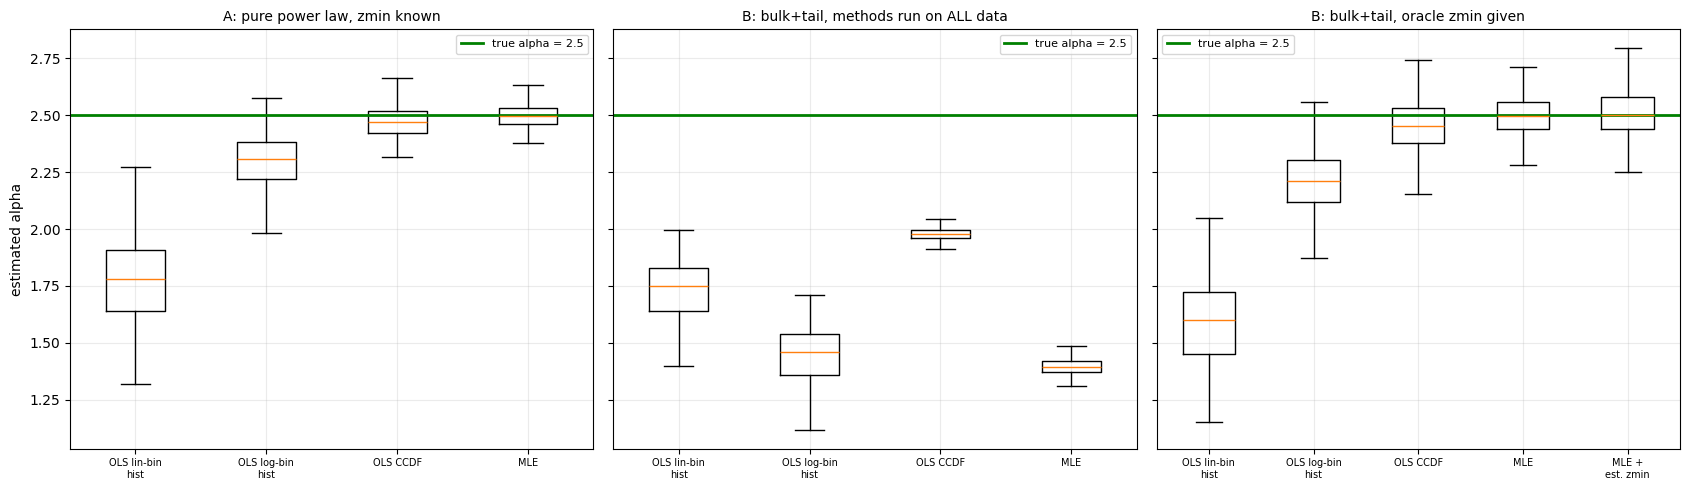

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
panels = [("A: pure power law, zmin known", A, None),
          ("B: bulk+tail, methods run on ALL data", Bn, None),
          ("B: bulk+tail, oracle zmin given", Bo, Bc)]
for ax, (title, d, extra) in zip(axes, panels):
    data = list(d.values())
    labels = [k.replace(" hist", "\nhist") for k in d.keys()]
    if extra is not None:
        data.append(extra); labels.append("MLE +\nest. zmin")
    ax.boxplot(data, tick_labels=labels, showfliers=False)
    ax.axhline(ALPHA_TRUE, color="g", lw=2, label="true alpha = 2.5")
    ax.set_title(title, fontsize=10); ax.tick_params(axis="x", labelsize=7); ax.legend(fontsize=8)
axes[0].set_ylabel("estimated alpha")
plt.tight_layout(); plt.show()

### What we see and infer
- **Panel A:** the boxes move up toward the green line from left to right. The MLE box is both centred on the line and short. The linear-bin box sits far below it.
- **Panel B (naive):** no box touches the green line. The MLE box is the shortest and is centred near 1.4. It is *precise but wrong*, as in the table.
- **Panel B (oracle):** with the right threshold, MLE is centred on the truth. The estimated-$z_{\min}$ box is slightly taller, which is the extra uncertainty we measured above.
- **Takeaway:** the height of a box (precision) does not tell you whether you are right (accuracy). In real data you cannot see the green line, so you must validate the model choices, in particular $z_{\min}$ and the goodness of fit, because the numbers alone will not reveal an error.

# Part 3: does more data fix the problem?

## Step 3.1: bias as a function of sample size
**What we do:** in scenario A (pure power law, so nothing else can go wrong), repeat the experiment for sample sizes $n = 50$ up to 3000 (200 replications each) and track the mean estimate with $\pm1$ standard deviation bars.

**Why:** this is the cleanest test of *consistency*. A good estimator converges to 2.5 as $n$ grows. If an estimator stays away from 2.5 even with plenty of data, its error is **systematic**, which is the paper's warning about log-log regression.

,OLS lin-bin hist,OLS log-bin hist,OLS CCDF,MLE
n,,,,
50,1.127,1.801,2.399,2.563
100,1.350,2.003,2.420,2.518
300,1.584,2.196,2.449,2.500
1000,1.774,2.304,2.476,2.502
3000,1.955,2.363,2.489,2.500


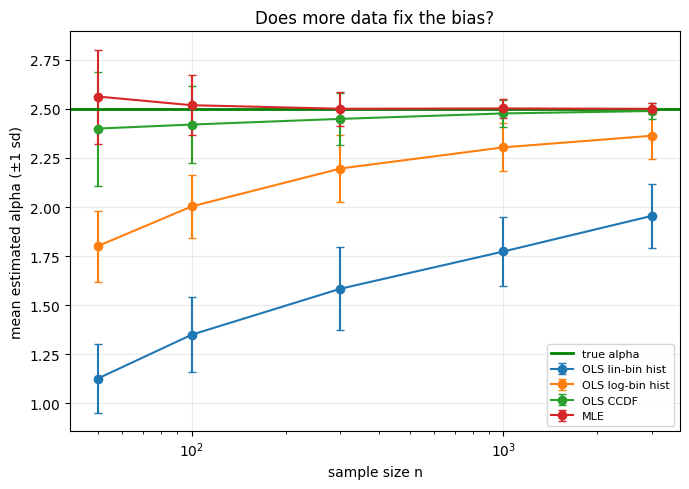

In [12]:
ns = [50, 100, 300, 1000, 3000]
means = {k: [] for k in ["OLS lin-bin hist", "OLS log-bin hist", "OLS CCDF", "MLE"]}
sds   = {k: [] for k in means}
for nn in ns:
    runs = collect([all_estimators(sample_powerlaw(nn, ALPHA_TRUE, 1.0, rng), 1.0)
                    for _ in range(200)])
    for k, v in runs.items():
        means[k].append(v.mean()); sds[k].append(v.std())

display(pd.DataFrame(means, index=pd.Index(ns, name="n")).round(3))

fig, ax = plt.subplots(figsize=(7, 5))
for k in means:
    ax.errorbar(ns, means[k], yerr=sds[k], marker="o", capsize=3, label=k)
ax.axhline(ALPHA_TRUE, color="g", lw=2, label="true alpha")
ax.set_xscale("log"); ax.set_xlabel("sample size n"); ax.set_ylabel("mean estimated alpha (±1 sd)")
ax.set_title("Does more data fix the bias?"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### What we see
| n | OLS lin-bin | OLS log-bin | OLS CCDF | MLE |
|---|---|---|---|---|
| 50 | 1.127 | 1.801 | 2.399 | 2.563 |
| 100 | 1.350 | 2.003 | 2.420 | 2.518 |
| 300 | 1.584 | 2.196 | 2.449 | 2.500 |
| 1000 | 1.774 | 2.304 | 2.476 | 2.502 |
| 3000 | 1.955 | 2.363 | 2.489 | 2.500 |

### What we infer
- **MLE converges quickly:** it is already at 2.500 by $n=300$. At $n=50$ it is slightly high (2.563). Theory says the plain MLE formula is biased upward by about $(\alpha-1)/(n-1)\approx0.03$ here. We see +0.06, which is larger but within roughly two simulation standard errors for 200 repetitions. In this simple setting, replacing $n$ by $n-1$ in the formula removes this bias.
- **The CCDF fit is consistent but slow:** bias −0.10 at $n=50$ and −0.011 at $n=3000$.
- **The log-bin fit** is still 0.14 low at $n=3000$.
- **The linear-bin fit** is the worst: 1.37 too low at $n=50$, and still 0.55 too low at 3000. Together with the sanity check in Step 1.1 (2.62 at $n=200{,}000$), it passes *through* the truth without ever settling on it, which means its value depends on the binning setup and the sample maximum rather than on a stable property of the distribution.
- **For real LOB studies,** this explains how different papers analysing similar data could report different exponents: sample size and binning choices change the answer for line-fit methods, while MLE gives comparable answers.

# Part 4: Conclusions

## What the experiments show
| Claim in the survey (III.J.1) | What our simulation showed |
|---|---|
| Least squares on a log-log plot gives *systematic* errors | Confirmed: histogram fits are biased by 0.2 to 0.7 in the clean case, and the bias does not vanish as $n$ grows |
| Clauset et al.: use maximum likelihood | Confirmed: unbiased from $n\approx300$ and the lowest scatter in every scenario |
| The power law must be tested, not assumed | Confirmed: MLE returned a plausible-looking 3.26 for a lognormal; only the bootstrap flagged it, and only just |
| $z_{\min}$ must be estimated | Confirmed: with the wrong threshold even MLE was off by about 1.1, with a small spread |

## A practical recipe, from what we found
1. Plot the CCDF on log-log axes and look at it first.
2. Estimate $z_{\min}$ and $\alpha$ together (KS minimisation).
3. Report the MLE with its standard error, not a regression slope.
4. Run a goodness-of-fit test, and compare with alternative distributions (lognormal, exponential, stretched exponential) before claiming a power law.
5. Report sample size and the tail size actually used.

## Limits of this experiment (important for using it in research)
- **The data are i.i.d.** Real LOB data are strongly autocorrelated and clustered (the paper's III.J and III.B), so the *effective* sample size is smaller than the number of rows. All our standard errors would then be too optimistic. This is the biggest gap between this demo and real data.
- **The data are continuous**, whereas order sizes are integer multiples of the lot size. The paper notes that continuous estimators on discrete data are another source of error; a discrete MLE would be needed.
- **One true shape and a few settings.** We used one $\alpha$, one bulk shape and fixed bin counts. The ranking of methods is robust, but the exact numbers are not.
- **The p-value is itself noisy** (200 bootstrap replications, a single sample), especially near the 0.1 cutoff.
- **Distinguishing a power law from a lognormal** needs more than one p-value; a likelihood-ratio comparison against the alternative is the standard next step.

## Exercises (the fastest way to build intuition)
1. Set `ALPHA_TRUE = 1.5`, then `3.5`. Do the biases change with the exponent? Which methods are most sensitive?
2. In `sample_bulk_plus_tail`, change `tail_frac` to 0.05 and then 0.6. How does the tail size change the quality of Clauset's $z_{\min}$ estimate?
3. Change `nb` in `ols_linbins` and `ols_logbins` (for example 10 and 100). How much do the OLS results move? This quantifies the "depends on arbitrary choices" point.
4. Replace the lognormal bulk with an exponential bulk. Is $z_{\min}$ easier or harder to find?
5. Make the data *dependent*: for example, draw each value from a power law whose scale follows a slowly varying random process. Compare the MLE's own standard error $(\hat\alpha-1)/\sqrt n$ with the real scatter over repeated runs. This links directly to the long-memory discussion in III.J.2.
6. Implement a discrete-data MLE, so you can apply this to lot-size data.

## Where this connects to your thesis
Every "power law with exponent X" quoted in Section IV of the survey was estimated by some method, usually older than this recommendation. A natural research-flavoured question is: *how many of the classic LOB exponents survive when re-estimated with MLE, a proper $z_{\min}$ and a goodness-of-fit test on recent data?* This is concrete, doable and publishable-sized, though whether it is novel enough needs a literature check, which we can do together.

**Next notebook (suggested):** the second half of III.J: simulate a long-memory series with a known Hurst exponent $H$ and compare R/S, DFA and periodogram estimators.